# Experimento de Previsão de Novos Anúncios do Trocabook

Este experimento tem como objetivo avaliar métodos para estimar a quantidade de novos anúncios que poderão ser anunciados no Trocabook em períodos futuros, utilizando como base o histórico mensal de criação de anúncios da plataforma.

A previsão será construída a partir do campo `dataCriacao` dos anúncios. Esse campo permitirá agrupar as publicações por mês e construir uma série temporal representando a quantidade de novos anúncios cadastrados em cada período.

O experimento utilizará inicialmente dados simulados, seguindo o mesmo cenário utilizado no experimento de análise de anúncios. Dessa forma, será possível validar as etapas de preparação da série temporal, análise exploratória, treinamento, avaliação dos modelos e geração de previsões antes da integração com os dados reais armazenados no Firebase Cloud Firestore.

A avaliação dos modelos será realizada respeitando a ordem cronológica dos dados. Parte do histórico será utilizada para treinamento e os períodos mais recentes serão reservados para teste, permitindo comparar as previsões produzidas pelos modelos com valores conhecidos. Também será utilizado um modelo baseline como referência para avaliar se os métodos preditivos testados apresentam desempenho adequado.

O desempenho será avaliado por meio de métricas de erro, como MAE (Mean Absolute Error) e RMSE (Root Mean Squared Error). Após a avaliação experimental, serão produzidas projeções da quantidade de novos anúncios para períodos futuros, considerando horizontes de 1, 3, 6 e 12 meses.

O objetivo deste experimento é exclusivamente prever a **quantidade de novos anúncios**. O modelo não buscará prever características dos anúncios futuros, como livro, categoria, autor, modalidade de negociação ou usuário anunciante.

Os resultados obtidos poderão posteriormente servir como base para a implementação da funcionalidade de previsão no serviço de Analytics e para a apresentação de indicadores no dashboard administrativo do Trocabook.

## 1. Bibliotecas utilizadas

Neste experimento serão utilizadas bibliotecas para manipulação dos dados, visualização da série temporal e construção e avaliação dos modelos de previsão.

O `Pandas` será utilizado para organizar, transformar e analisar os dados dos anúncios. O `NumPy` auxiliará em operações numéricas, enquanto o `Matplotlib` será utilizado para a visualização da evolução temporal dos anúncios.

Para a etapa preditiva, o `scikit-learn` será utilizado na construção dos modelos experimentais e no cálculo das métricas utilizadas para avaliar o desempenho das previsões.

In [130]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

## 2. Dados utilizados no experimento

Para validar a metodologia de previsão antes da integração com o Firebase Cloud Firestore, será utilizado inicialmente um conjunto de dados simulados representando anúncios publicados no Trocabook.

Os dados simulados buscarão representar os principais campos do anúncio necessários para construir e validar o experimento. Entre eles estão o identificador do anúncio, o usuário anunciante, o livro anunciado, o tipo de negociação, o título, os autores, as categorias e a data de criação.

Embora o modelo real de anúncio possua outros campos utilizados pelo funcionamento da plataforma, a previsão desenvolvida neste experimento utilizará principalmente o campo `dataCriacao`, responsável por permitir a construção do histórico mensal de novos anúncios.

Os anúncios serão distribuídos ao longo de diferentes períodos, possibilitando posteriormente transformar os registros individuais em uma série temporal da quantidade de novos anúncios por mês.

### 2.1 Simulação dos anúncios

Como o experimento ainda não está integrado ao Firebase Cloud Firestore, será utilizado o mesmo cenário de dados simulados empregado no experimento de análise de anúncios do Trocabook.

A simulação utilizará diferentes livros, autores, categorias e modalidades de negociação. Os anúncios serão distribuídos ao longo do tempo por meio do campo `dataCriacao`, permitindo posteriormente construir uma série temporal da quantidade de novos anúncios por mês.

Os dados simulados não têm como objetivo reproduzir exatamente o comportamento futuro da plataforma, mas fornecer uma base controlada para validar as etapas de preparação da série temporal, treinamento, avaliação dos modelos e geração de previsões.

In [131]:
titulos_simulados = [
    "Dom Casmurro",
    "O Hobbit",
    "1984",
    "Orgulho e Preconceito",
    "O Pequeno Príncipe",
    "Harry Potter e a Pedra Filosofal",
    "Clean Code",
    "O Senhor dos Anéis",
    "A Revolução dos Bichos",
    "Percy Jackson e o Ladrão de Raios"
]

autores_simulados = [
    ["Machado de Assis"],
    ["J. R. R. Tolkien"],
    ["George Orwell"],
    ["Jane Austen"],
    ["Antoine de Saint-Exupéry"],
    ["J. K. Rowling"],
    ["Robert C. Martin"],
    ["J. R. R. Tolkien"],
    ["George Orwell"],
    ["Rick Riordan"]
]

categorias_simuladas = [
    ["Literatura Brasileira", "Clássicos"],
    ["Fantasia", "Aventura"],
    ["Ficção", "Clássicos"],
    ["Romance", "Clássicos"],
    ["Ficção", "Infantojuvenil"],
    ["Fantasia", "Infantojuvenil"],
    ["Tecnologia", "Programação"],
    ["Fantasia", "Aventura"],
    ["Ficção", "Clássicos"],
    ["Fantasia", "Aventura"]
]

Para representar a evolução das publicações ao longo do tempo, serão utilizados 36 meses de histórico de anúncios.

A quantidade de novos anúncios variará entre os meses, apresentando uma tendência geral de crescimento acompanhada de oscilações. Essa distribuição será independente daquela utilizada no experimento de previsão de usuários, evitando estabelecer artificialmente uma relação direta entre o crescimento de usuários e a quantidade de anúncios publicados.

Essa dimensão temporal será posteriormente utilizada para construir a série histórica mensal que servirá como base para o treinamento e a avaliação dos modelos de previsão.

In [132]:
anuncios_por_mes_simulados = [
    25, 28, 26, 31, 29, 33,
    30, 35, 32, 38, 36, 40,
    37, 42, 39, 45, 43, 47,
    44, 50, 46, 52, 49, 55,
    51, 57, 54, 60, 56, 63,
    59, 65, 62, 68, 64, 70
]

In [133]:
meses_simulados = pd.period_range(
    start="2024-01",
    periods=36,
    freq="M"
)

meses_simulados

PeriodIndex(['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06',
             '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12',
             '2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06',
             '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12',
             '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06',
             '2026-07', '2026-08', '2026-09', '2026-10', '2026-11', '2026-12'],
            dtype='period[M]')

Para gerar os registros individuais dos anúncios, serão utilizadas distribuições controladas para a seleção dos livros e das modalidades de negociação.

A geração será realizada de forma reprodutível, permitindo que os mesmos dados simulados sejam obtidos sempre que o notebook for executado. Alguns livros poderão aparecer com maior frequência que outros, representando diferenças na quantidade de anúncios publicados.

Embora essas características façam parte da geração dos dados simulados, elas não serão utilizadas como variáveis para prever os anúncios futuros. Neste experimento, a previsão será baseada na evolução histórica da quantidade mensal de novos anúncios.

In [134]:
rng = np.random.default_rng(42)

In [135]:
probabilidades_livros = [
    0.08,
    0.14,
    0.11,
    0.07,
    0.10,
    0.13,
    0.06,
    0.12,
    0.09,
    0.10
]

sum(probabilidades_livros)

1.0

In [136]:
tipos_negociacao = [
    "TROCA",
    "VENDA",
    "AMBOS"
]

probabilidades_tipos = [
    0.40,
    0.35,
    0.25
]

sum(probabilidades_tipos)

1.0

In [137]:
anuncios_simulados = []

contador_anuncio = 1

for mes, quantidade in zip(
    meses_simulados,
    anuncios_por_mes_simulados
):
    for _ in range(quantidade):

        indice_livro = rng.choice(
            len(titulos_simulados),
            p=probabilidades_livros
        )

        tipo_negociacao = rng.choice(
            tipos_negociacao,
            p=probabilidades_tipos
        )

        anuncios_simulados.append({
            "id": f"A{contador_anuncio}",
            "uidUsuario": f"U{rng.integers(1, 201)}",
            "uidLivro": f"L{indice_livro + 1}",
            "titulo": titulos_simulados[indice_livro],
            "autores": autores_simulados[indice_livro],
            "categorias": categorias_simuladas[indice_livro],
            "tipoNegociacao": tipo_negociacao,
            "dataCriacao": mes.to_timestamp()
        })

        contador_anuncio += 1

In [138]:
anuncios = pd.DataFrame(anuncios_simulados)

anuncios.head()

,id,uidUsuario,uidLivro,titulo,autores,categorias,tipoNegociacao,dataCriacao
0,A1,U87,L8,O Senhor dos Anéis,[J. R. R. Tolkien],"[Fantasia, Aventura]",VENDA,2024-01-01
1,A2,U172,L8,O Senhor dos Anéis,[J. R. R. Tolkien],"[Fantasia, Aventura]",TROCA,2024-01-01
2,A3,U144,L10,Percy Jackson e o Ladrão de Raios,[Rick Riordan],"[Fantasia, Aventura]",AMBOS,2024-01-01
3,A4,U158,L2,O Hobbit,[J. R. R. Tolkien],"[Fantasia, Aventura]",VENDA,2024-01-01
4,A5,U157,L4,Orgulho e Preconceito,[Jane Austen],"[Romance, Clássicos]",AMBOS,2024-01-01


In [139]:
anuncios.tail()

,id,uidUsuario,uidLivro,titulo,autores,categorias,tipoNegociacao,dataCriacao
1656,A1657,U160,L4,Orgulho e Preconceito,[Jane Austen],"[Romance, Clássicos]",VENDA,2026-12-01
1657,A1658,U7,L4,Orgulho e Preconceito,[Jane Austen],"[Romance, Clássicos]",VENDA,2026-12-01
1658,A1659,U20,L3,1984,[George Orwell],"[Ficção, Clássicos]",TROCA,2026-12-01
1659,A1660,U139,L5,O Pequeno Príncipe,[Antoine de Saint-Exupéry],"[Ficção, Infantojuvenil]",VENDA,2026-12-01
1660,A1661,U66,L3,1984,[George Orwell],"[Ficção, Clássicos]",VENDA,2026-12-01


### 2.2 Visualização inicial

Após a geração dos dados simulados, será realizada uma inspeção inicial do conjunto de anúncios para verificar sua estrutura, quantidade de registros, tipos de dados e possíveis valores ausentes.

Essa etapa permite identificar eventuais inconsistências antes da preparação da série temporal utilizada no experimento de previsão.

In [140]:
anuncios.shape

(1661, 8)

In [141]:
anuncios.info()

<class 'pandas.DataFrame'>
RangeIndex: 1661 entries, 0 to 1660
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              1661 non-null   str           
 1   uidUsuario      1661 non-null   str           
 2   uidLivro        1661 non-null   str           
 3   titulo          1661 non-null   str           
 4   autores         1661 non-null   object        
 5   categorias      1661 non-null   object        
 6   tipoNegociacao  1661 non-null   str           
 7   dataCriacao     1661 non-null   datetime64[us]
dtypes: datetime64[us](1), object(2), str(5)
memory usage: 103.9+ KB


In [142]:
anuncios.isnull().sum()

id                0
uidUsuario        0
uidLivro          0
titulo            0
autores           0
categorias        0
tipoNegociacao    0
dataCriacao       0
dtype: int64

In [143]:
print(f"Quantidade de anúncios: {len(anuncios)}")
print(f"Quantidade de usuários anunciantes: {anuncios['uidUsuario'].nunique()}")
print(f"Quantidade de livros diferentes: {anuncios['uidLivro'].nunique()}")
print(f"Período inicial: {anuncios['dataCriacao'].min()}")
print(f"Período final: {anuncios['dataCriacao'].max()}")

Quantidade de anúncios: 1661
Quantidade de usuários anunciantes: 200
Quantidade de livros diferentes: 10
Período inicial: 2024-01-01 00:00:00
Período final: 2026-12-01 00:00:00


## 3. Preparação da série temporal

Para realizar a previsão da quantidade de novos anúncios, os registros individuais serão transformados em uma série temporal mensal.

O campo `dataCriacao` será utilizado para identificar o mês de criação de cada anúncio. Em seguida, os anúncios serão agrupados por mês, obtendo-se a quantidade de novos anúncios publicados em cada período.

Essa transformação permitirá representar o histórico de anúncios como uma sequência cronológica de valores, que posteriormente será utilizada no treinamento e na avaliação dos modelos de previsão.

In [144]:
anuncios["mesCriacao"] = (
    anuncios["dataCriacao"]
    .dt.to_period("M")
)

anuncios[
    ["id", "dataCriacao", "mesCriacao"]
].head()

,id,dataCriacao,mesCriacao
0,A1,2024-01-01,2024-01
1,A2,2024-01-01,2024-01
2,A3,2024-01-01,2024-01
3,A4,2024-01-01,2024-01
4,A5,2024-01-01,2024-01


In [145]:
anuncios[["id", "dataCriacao", "mesCriacao"]].tail()

,id,dataCriacao,mesCriacao
1656,A1657,2026-12-01,2026-12
1657,A1658,2026-12-01,2026-12
1658,A1659,2026-12-01,2026-12
1659,A1660,2026-12-01,2026-12
1660,A1661,2026-12-01,2026-12


### 3.1 Quantidade de novos anúncios por mês

Após a identificação do mês de criação de cada anúncio, os registros serão agrupados mensalmente para obter a quantidade de novos anúncios publicados em cada período.

O resultado desse agrupamento formará a série temporal utilizada nas próximas etapas do experimento de previsão.

In [146]:
serie_anuncios = (
    anuncios
    .groupby("mesCriacao")
    .size()
    .reset_index(name="novosAnuncios")
)

serie_anuncios

,mesCriacao,novosAnuncios
0,2024-01,25
1,2024-02,28
2,2024-03,26
3,2024-04,31
4,2024-05,29
5,2024-06,33
6,2024-07,30
7,2024-08,35
8,2024-09,32
9,2024-10,38


In [147]:
serie_anuncios.tail()

,mesCriacao,novosAnuncios
31,2026-08,65
32,2026-09,62
33,2026-10,68
34,2026-11,64
35,2026-12,70


In [148]:
print(f"Quantidade de meses: {len(serie_anuncios)}")
print(f"Total de anúncios na série: {serie_anuncios['novosAnuncios'].sum()}")
print(f"Total de anúncios original: {len(anuncios)}")

Quantidade de meses: 36
Total de anúncios na série: 1661
Total de anúncios original: 1661


### 3.2 Tratamento de meses sem anúncios

Em uma série temporal mensal, é importante garantir que todos os meses entre o início e o fim do período analisado estejam representados.

Caso nenhum anúncio seja publicado em determinado mês, esse período não será criado automaticamente pelo agrupamento realizado anteriormente. Para preservar a continuidade da série temporal, meses ausentes devem ser adicionados com quantidade igual a zero.

In [149]:
periodo_completo = pd.period_range(
    start=serie_anuncios["mesCriacao"].min(),
    end=serie_anuncios["mesCriacao"].max(),
    freq="M"
)

periodo_completo

PeriodIndex(['2024-01', '2024-02', '2024-03', '2024-04', '2024-05', '2024-06',
             '2024-07', '2024-08', '2024-09', '2024-10', '2024-11', '2024-12',
             '2025-01', '2025-02', '2025-03', '2025-04', '2025-05', '2025-06',
             '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12',
             '2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06',
             '2026-07', '2026-08', '2026-09', '2026-10', '2026-11', '2026-12'],
            dtype='period[M]')

In [150]:
serie_anuncios = (
    serie_anuncios
    .set_index("mesCriacao")
    .reindex(periodo_completo, fill_value=0)
    .rename_axis("mesCriacao")
    .reset_index()
)

serie_anuncios

,mesCriacao,novosAnuncios
0,2024-01,25
1,2024-02,28
2,2024-03,26
3,2024-04,31
4,2024-05,29
5,2024-06,33
6,2024-07,30
7,2024-08,35
8,2024-09,32
9,2024-10,38


In [151]:
serie_anuncios.tail()

,mesCriacao,novosAnuncios
31,2026-08,65
32,2026-09,62
33,2026-10,68
34,2026-11,64
35,2026-12,70


In [152]:
print(f"Quantidade de meses após o tratamento: {len(serie_anuncios)}")
print(f"Total de anúncios após o tratamento: {serie_anuncios['novosAnuncios'].sum()}")
print(f"Meses com zero anúncios: {(serie_anuncios['novosAnuncios'] == 0).sum()}")

Quantidade de meses após o tratamento: 36
Total de anúncios após o tratamento: 1661
Meses com zero anúncios: 0


## 4. Análise exploratória da evolução dos anúncios

Antes da construção dos modelos de previsão, será realizada uma análise exploratória da série temporal para compreender o comportamento histórico da quantidade de novos anúncios.

Nesta etapa serão observadas estatísticas descritivas, a evolução dos anúncios ao longo dos meses e a tendência apresentada pelos dados simulados.

Essa análise é importante para compreender as características da série antes da aplicação e avaliação dos métodos de previsão.

### 4.1 Estatísticas descritivas

Inicialmente, serão calculadas estatísticas descritivas da quantidade mensal de novos anúncios, permitindo observar valores como média, desvio padrão, mínimo, máximo e quartis da série temporal.

In [153]:
serie_anuncios["novosAnuncios"].describe()

count    36.000000
mean     46.138889
std      12.970632
min      25.000000
25%      35.750000
50%      45.500000
75%      56.250000
max      70.000000
Name: novosAnuncios, dtype: float64

### 4.2 Evolução histórica dos anúncios

Após a análise das estatísticas descritivas, será observada a evolução da quantidade de novos anúncios ao longo dos meses.

A visualização da série temporal permite identificar tendências, oscilações e possíveis mudanças no comportamento dos dados ao longo do período analisado.

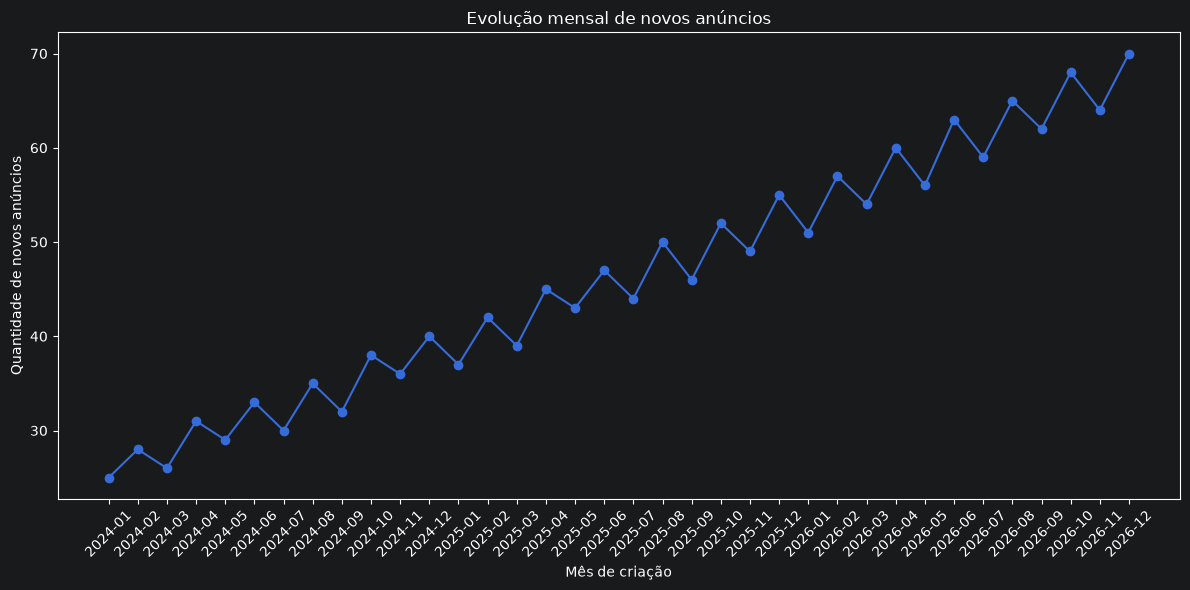

In [154]:
plt.figure(figsize=(12, 6))

plt.plot(
    serie_anuncios["mesCriacao"].astype(str),
    serie_anuncios["novosAnuncios"],
    marker="o"
)

plt.title("Evolução mensal de novos anúncios")
plt.xlabel("Mês de criação")
plt.ylabel("Quantidade de novos anúncios")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### 4.3 Evolução entre o início e o fim da série

Para complementar a análise visual, será calculada a variação entre a quantidade de novos anúncios observada no primeiro e no último mês da série temporal.

Essa comparação permite quantificar o crescimento apresentado pelos dados simulados ao longo do período analisado.

In [155]:
primeiro_valor = serie_anuncios["novosAnuncios"].iloc[0]
ultimo_valor = serie_anuncios["novosAnuncios"].iloc[-1]

crescimento_absoluto = ultimo_valor - primeiro_valor

crescimento_percentual = (
    crescimento_absoluto
    / primeiro_valor
    * 100
)

print(f"Primeiro mês: {primeiro_valor} anúncios")
print(f"Último mês: {ultimo_valor} anúncios")
print(f"Crescimento absoluto: {crescimento_absoluto} anúncios")
print(f"Crescimento percentual: {crescimento_percentual:.2f}%")

Primeiro mês: 25 anúncios
Último mês: 70 anúncios
Crescimento absoluto: 45 anúncios
Crescimento percentual: 180.00%


### 4.4 Média móvel

Para facilitar a visualização da tendência da série temporal, será calculada uma média móvel considerando os últimos três meses.

A média móvel suaviza oscilações de curto prazo ao calcular, para cada período, a média das observações mais recentes. Neste experimento, ela será utilizada apenas como ferramenta de análise exploratória e não como modelo de previsão.

In [156]:
serie_anuncios["mediaMovel3Meses"] = (
    serie_anuncios["novosAnuncios"]
    .rolling(window=3)
    .mean()
)

serie_anuncios.head(10)

,mesCriacao,novosAnuncios,mediaMovel3Meses
0,2024-01,25,NaN
1,2024-02,28,NaN
2,2024-03,26,26.333333
3,2024-04,31,28.333333
4,2024-05,29,28.666667
5,2024-06,33,31.000000
6,2024-07,30,30.666667
7,2024-08,35,32.666667
8,2024-09,32,32.333333
9,2024-10,38,35.000000


In [157]:
serie_anuncios.tail(10)

,mesCriacao,novosAnuncios,mediaMovel3Meses
26,2026-03,54,54.000000
27,2026-04,60,57.000000
28,2026-05,56,56.666667
29,2026-06,63,59.666667
30,2026-07,59,59.333333
31,2026-08,65,62.333333
32,2026-09,62,62.000000
33,2026-10,68,65.000000
34,2026-11,64,64.666667
35,2026-12,70,67.333333


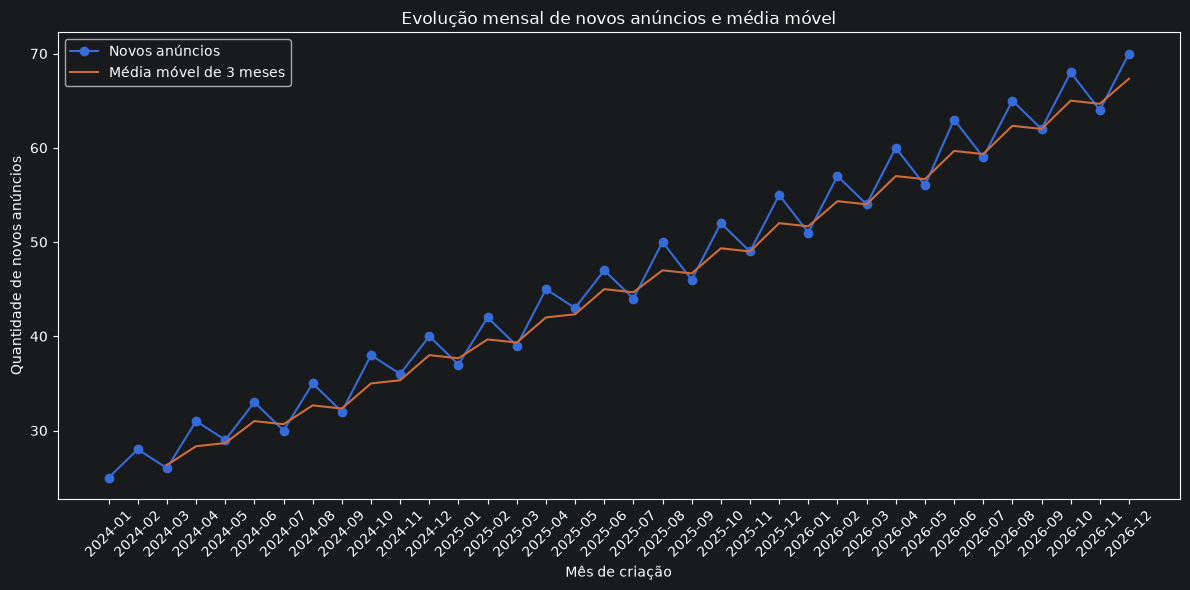

In [158]:
plt.figure(figsize=(12, 6))

plt.plot(
    serie_anuncios["mesCriacao"].astype(str),
    serie_anuncios["novosAnuncios"],
    marker="o",
    label="Novos anúncios"
)

plt.plot(
    serie_anuncios["mesCriacao"].astype(str),
    serie_anuncios["mediaMovel3Meses"],
    label="Média móvel de 3 meses"
)

plt.title("Evolução mensal de novos anúncios e média móvel")
plt.xlabel("Mês de criação")
plt.ylabel("Quantidade de novos anúncios")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.show()

## 5. Preparação para a previsão

Após a preparação e análise exploratória da série temporal, os dados serão organizados para a avaliação dos métodos de previsão.

Como os registros possuem uma ordem cronológica, a separação entre dados de treinamento e teste será realizada preservando a sequência temporal. Os períodos mais antigos serão utilizados para treinamento, enquanto os meses mais recentes serão reservados para avaliar as previsões produzidas pelos modelos.

Essa abordagem evita utilizar informações futuras durante o treinamento e permite simular de forma mais adequada uma situação real de previsão.

### 5.1 Separação entre treino e teste

Para avaliar os métodos de previsão, os últimos seis meses da série serão utilizados como conjunto de teste. Os meses anteriores serão utilizados como conjunto de treinamento.

A divisão será realizada de forma cronológica, sem embaralhar os registros, preservando a ordem temporal dos dados.

### 5.2 Baseline de persistência

Antes da aplicação de modelos preditivos, será utilizado um baseline de persistência como referência para a avaliação das previsões.

Nesse método, a previsão para o próximo mês corresponde à quantidade de anúncios observada no mês imediatamente anterior. Dessa forma, será possível verificar posteriormente se os modelos experimentais conseguem produzir previsões com erros menores do que uma estratégia simples baseada no último valor conhecido.

O baseline não representa o modelo final de previsão, mas funciona como uma referência mínima para comparação de desempenho.

In [159]:
quantidade_teste = 6

treino = serie_anuncios.iloc[:-quantidade_teste].copy()
teste = serie_anuncios.iloc[-quantidade_teste:].copy()

print(f"Quantidade de meses para treinamento: {len(treino)}")
print(f"Quantidade de meses para teste: {len(teste)}")

print(
    f"Período de treinamento: "
    f"{treino['mesCriacao'].iloc[0]} até "
    f"{treino['mesCriacao'].iloc[-1]}"
)

print(
    f"Período de teste: "
    f"{teste['mesCriacao'].iloc[0]} até "
    f"{teste['mesCriacao'].iloc[-1]}"
)

Quantidade de meses para treinamento: 30
Quantidade de meses para teste: 6
Período de treinamento: 2024-01 até 2026-06
Período de teste: 2026-07 até 2026-12


In [160]:
previsoes_baseline = []

ultimo_valor = treino["novosAnuncios"].iloc[-1]

for valor_real in teste["novosAnuncios"]:
    previsoes_baseline.append(ultimo_valor)
    ultimo_valor = valor_real

previsoes_baseline

[np.int64(63), 59, 65, 62, 68, 64]

In [161]:
resultado_baseline = teste[
    ["mesCriacao", "novosAnuncios"]
].copy()

resultado_baseline["previsaoBaseline"] = previsoes_baseline

resultado_baseline

,mesCriacao,novosAnuncios,previsaoBaseline
30,2026-07,59,63
31,2026-08,65,59
32,2026-09,62,65
33,2026-10,68,62
34,2026-11,64,68
35,2026-12,70,64


### 5.3 Avaliação do baseline

O desempenho do baseline será avaliado utilizando as métricas MAE (Mean Absolute Error) e RMSE (Root Mean Squared Error).

O MAE representa a média das diferenças absolutas entre os valores reais e previstos, enquanto o RMSE atribui maior peso aos erros de maior magnitude por elevar as diferenças ao quadrado antes do cálculo da média.

Quanto menores os valores dessas métricas, menor é o erro das previsões realizadas.

In [162]:
mae_baseline = mean_absolute_error(
    teste["novosAnuncios"],
    previsoes_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(
        teste["novosAnuncios"],
        previsoes_baseline
    )
)

print(f"MAE do baseline: {mae_baseline:.2f}")
print(f"RMSE do baseline: {rmse_baseline:.2f}")

MAE do baseline: 4.83
RMSE do baseline: 4.98


## 6. Modelo preditivo

Após a definição e avaliação do baseline, será testado um modelo de Regressão Linear para representar a tendência da quantidade de novos anúncios ao longo do tempo.

Para utilizar a Regressão Linear, cada mês da série será representado por um índice temporal numérico. Esse índice funcionará como variável de entrada do modelo, enquanto a quantidade de novos anúncios será utilizada como variável alvo.

O desempenho do modelo será avaliado utilizando o mesmo período de teste e as mesmas métricas aplicadas ao baseline, permitindo comparar os resultados obtidos pelos dois métodos.

A Regressão Linear será utilizada como modelo experimental e sua aplicação não implica que ela seja o modelo definitivo para os dados reais do Trocabook.

### 6.1 Criação do índice temporal

Para que a Regressão Linear possa representar a evolução dos anúncios ao longo do tempo, será criado um índice temporal numérico para cada mês da série.

O primeiro mês receberá o índice `0`, o segundo o índice `1` e assim sucessivamente. Dessa forma, o modelo poderá relacionar a passagem do tempo com a quantidade mensal de novos anúncios.

In [163]:
serie_anuncios["indiceTempo"] = np.arange(
    len(serie_anuncios)
)

serie_anuncios[
    ["mesCriacao", "indiceTempo", "novosAnuncios"]
].head(10)

,mesCriacao,indiceTempo,novosAnuncios
0,2024-01,0,25
1,2024-02,1,28
2,2024-03,2,26
3,2024-04,3,31
4,2024-05,4,29
5,2024-06,5,33
6,2024-07,6,30
7,2024-08,7,35
8,2024-09,8,32
9,2024-10,9,38


In [164]:
serie_anuncios[
    ["mesCriacao", "indiceTempo", "novosAnuncios"]
].tail(10)

,mesCriacao,indiceTempo,novosAnuncios
26,2026-03,26,54
27,2026-04,27,60
28,2026-05,28,56
29,2026-06,29,63
30,2026-07,30,59
31,2026-08,31,65
32,2026-09,32,62
33,2026-10,33,68
34,2026-11,34,64
35,2026-12,35,70


### 6.2 Preparação dos dados de treino e teste

Após a criação do índice temporal, serão definidas as variáveis utilizadas pela Regressão Linear.

O `indiceTempo` será utilizado como variável de entrada (`X`), representando a passagem dos meses, enquanto `novosAnuncios` será utilizado como variável alvo (`y`), representando a quantidade de novos anúncios observada em cada período.

A mesma divisão cronológica definida anteriormente será mantida, utilizando os primeiros 30 meses para treinamento e os últimos 6 meses para teste.

In [165]:
treino = serie_anuncios.iloc[:-quantidade_teste].copy()
teste = serie_anuncios.iloc[-quantidade_teste:].copy()

In [166]:
X_treino = treino[["indiceTempo"]]
y_treino = treino["novosAnuncios"]

X_teste = teste[["indiceTempo"]]
y_teste = teste["novosAnuncios"]

print(f"X treino: {X_treino.shape}")
print(f"y treino: {y_treino.shape}")
print(f"X teste: {X_teste.shape}")
print(f"y teste: {y_teste.shape}")

X treino: (30, 1)
y treino: (30,)
X teste: (6, 1)
y teste: (6,)


### 6.3 Treinamento da Regressão Linear

Com os dados de treinamento preparados, será criado e treinado um modelo de Regressão Linear.

O modelo buscará identificar uma relação linear entre o avanço dos meses, representado pelo `indiceTempo`, e a quantidade de novos anúncios observada em cada período.

Após o treinamento, serão analisados o coeficiente e o intercepto encontrados pelo modelo, permitindo compreender a tendência linear estimada para a série.

In [167]:
modelo_regressao = LinearRegression()

modelo_regressao.fit(
    X_treino,
    y_treino
)

print(
    f"Coeficiente: "
    f"{modelo_regressao.coef_[0]:.4f}"
)

print(
    f"Intercepto: "
    f"{modelo_regressao.intercept_:.4f}"
)

Coeficiente: 1.1931
Intercepto: 25.1333


### 6.4 Previsões no conjunto de teste

Após o treinamento, o modelo será utilizado para estimar a quantidade de novos anúncios nos seis meses reservados para teste.

Como esses períodos não foram utilizados durante o treinamento da Regressão Linear, será possível comparar as previsões produzidas pelo modelo com os valores reais observados e posteriormente calcular suas métricas de erro.

In [168]:
previsoes_regressao = modelo_regressao.predict(
    X_teste
)

previsoes_regressao

array([60.92643678, 62.11954023, 63.31264368, 64.50574713, 65.69885057,
       66.89195402])

In [169]:
resultado_regressao = teste[
    ["mesCriacao", "novosAnuncios"]
].copy()

resultado_regressao["previsaoRegressao"] = (
    previsoes_regressao
)

resultado_regressao

,mesCriacao,novosAnuncios,previsaoRegressao
30,2026-07,59,60.926437
31,2026-08,65,62.119540
32,2026-09,62,63.312644
33,2026-10,68,64.505747
34,2026-11,64,65.698851
35,2026-12,70,66.891954


### 6.5 Avaliação da Regressão Linear

O desempenho da Regressão Linear será avaliado utilizando as mesmas métricas aplicadas ao baseline: MAE e RMSE.

A utilização das mesmas métricas e do mesmo conjunto de teste permite realizar uma comparação direta entre os dois métodos e verificar qual deles apresentou os menores erros na estimativa da quantidade mensal de novos anúncios.

In [170]:
mae_regressao = mean_absolute_error(
    y_teste,
    previsoes_regressao
)

rmse_regressao = np.sqrt(
    mean_squared_error(
        y_teste,
        previsoes_regressao
    )
)

print(f"MAE da regressão: {mae_regressao:.2f}")
print(f"RMSE da regressão: {rmse_regressao:.2f}")

MAE da regressão: 2.40
RMSE da regressão: 2.53


### 6.6 Comparação entre a Regressão Linear e o baseline

Após a avaliação individual dos métodos, seus resultados serão comparados para identificar qual apresentou o melhor desempenho no conjunto de teste.

Como MAE e RMSE representam medidas de erro, valores menores indicam previsões mais próximas das quantidades realmente observadas.

In [171]:
comparacao_modelos = pd.DataFrame({
    "modelo": [
        "Baseline de persistência",
        "Regressão Linear"
    ],
    "MAE": [
        mae_baseline,
        mae_regressao
    ],
    "RMSE": [
        rmse_baseline,
        rmse_regressao
    ]
})

comparacao_modelos

,modelo,MAE,RMSE
0,Baseline de persistência,4.833333,4.983305
1,Regressão Linear,2.403448,2.532689


A Regressão Linear apresentou valores de MAE e RMSE inferiores aos obtidos pelo baseline de persistência no conjunto de teste.

O MAE da Regressão Linear foi de aproximadamente 2,40 anúncios, enquanto o baseline apresentou um MAE de aproximadamente 4,83 anúncios. Da mesma forma, o RMSE foi reduzido de aproximadamente 4,98 para 2,53 anúncios.

Esses resultados indicam que, para os dados simulados utilizados neste experimento, a representação da tendência temporal por meio da Regressão Linear produziu estimativas mais próximas dos valores observados do que a estratégia de persistência.

Entretanto, esse resultado não determina que a Regressão Linear será o modelo definitivo do Trocabook. Com a utilização dos dados reais da plataforma, o desempenho deverá ser novamente avaliado e comparado com o baseline e, caso necessário, com outros métodos de previsão.

#### Considerações sobre os hiperparâmetros

A Regressão Linear utilizada neste experimento possui poucos hiperparâmetros relacionados diretamente ao processo de aprendizagem. Por esse motivo, não foi realizada uma etapa específica de otimização de hiperparâmetros.

Foi mantida a configuração padrão com intercepto, permitindo que o modelo estime livremente a relação entre o tempo e a quantidade de novos anúncios.

A avaliação experimental concentrou-se na comparação do desempenho da Regressão Linear com o baseline de persistência. Com a utilização futura dos dados reais do Trocabook, outros modelos e configurações poderão ser avaliados caso as características da série temporal justifiquem maior complexidade.

## 7. Previsões futuras

Após a avaliação da Regressão Linear no conjunto de teste, o modelo será utilizado para realizar projeções da quantidade de novos anúncios em períodos futuros.

Para essa etapa, o modelo será treinado novamente utilizando todo o histórico disponível, incluindo os meses anteriormente reservados para teste. Dessa forma, as projeções futuras poderão considerar todas as observações conhecidas da série temporal.

Serão realizadas projeções mensais para os próximos 12 meses e, posteriormente, esses resultados serão utilizados para estimar a quantidade de novos anúncios nos horizontes de 1, 3, 6 e 12 meses.

### 7.1 Treinamento com o histórico completo

Durante a avaliação do modelo, os últimos seis meses foram separados do treinamento para permitir a comparação das previsões com valores reais não utilizados durante o ajuste da Regressão Linear.

Após essa avaliação, o modelo será treinado novamente utilizando os 36 meses disponíveis. Assim, a geração das projeções futuras utilizará todo o histórico conhecido da série.

In [172]:
X_completo = serie_anuncios[["indiceTempo"]]
y_completo = serie_anuncios["novosAnuncios"]

modelo_regressao_final = LinearRegression()

modelo_regressao_final.fit(
    X_completo,
    y_completo
)

print(
    f"Coeficiente final: "
    f"{modelo_regressao_final.coef_[0]:.4f}"
)

print(
    f"Intercepto final: "
    f"{modelo_regressao_final.intercept_:.4f}"
)

Coeficiente final: 1.2127
Intercepto final: 24.9159


### 7.2 Projeção dos próximos 12 meses

Com o modelo treinado utilizando todo o histórico disponível, serão realizadas projeções para os 12 meses seguintes ao último período observado.

Como a série histórica termina em dezembro de 2026, os novos índices temporais representarão os meses de janeiro a dezembro de 2027. Esses índices serão fornecidos ao modelo para estimar a quantidade de novos anúncios em cada mês futuro.

In [173]:
quantidade_meses_futuros = 12

ultimo_indice = serie_anuncios["indiceTempo"].iloc[-1]

indices_futuros = np.arange(
    ultimo_indice + 1,
    ultimo_indice + quantidade_meses_futuros + 1
)

indices_futuros

array([36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47])

In [174]:
X_futuro = pd.DataFrame({
    "indiceTempo": indices_futuros
})

X_futuro

,indiceTempo
0,36
1,37
2,38
3,39
4,40
5,41
6,42
7,43
8,44
9,45


In [175]:
previsoes_futuras = modelo_regressao_final.predict(
    X_futuro
)

previsoes_futuras

array([68.57460317, 69.78734449, 71.0000858 , 72.21282711, 73.42556843,
       74.63830974, 75.85105105, 77.06379236, 78.27653368, 79.48927499,
       80.7020163 , 81.91475761])

### 7.3 Organização das projeções futuras

As previsões produzidas pelo modelo serão associadas aos respectivos meses futuros para facilitar sua interpretação e posterior utilização no Dashboard.

Como o último período observado corresponde a dezembro de 2026, será criada uma sequência mensal de janeiro a dezembro de 2027 e cada período será associado ao seu índice temporal e à quantidade de novos anúncios estimada pelo modelo.

In [176]:
ultimo_mes = serie_anuncios["mesCriacao"].iloc[-1]

meses_futuros = pd.period_range(
    start=ultimo_mes + 1,
    periods=quantidade_meses_futuros,
    freq="M"
)

meses_futuros

PeriodIndex(['2027-01', '2027-02', '2027-03', '2027-04', '2027-05', '2027-06',
             '2027-07', '2027-08', '2027-09', '2027-10', '2027-11', '2027-12'],
            dtype='period[M]')

In [177]:
projecoes_futuras = pd.DataFrame({
    "mes": meses_futuros,
    "indiceTempo": indices_futuros,
    "novosAnunciosEstimados": previsoes_futuras
})

projecoes_futuras

,mes,indiceTempo,novosAnunciosEstimados
0,2027-01,36,68.574603
1,2027-02,37,69.787344
2,2027-03,38,71.000086
3,2027-04,39,72.212827
4,2027-05,40,73.425568
5,2027-06,41,74.638310
6,2027-07,42,75.851051
7,2027-08,43,77.063792
8,2027-09,44,78.276534
9,2027-10,45,79.489275


In [178]:
projecoes_futuras.tail()

,mes,indiceTempo,novosAnunciosEstimados
7,2027-08,43,77.063792
8,2027-09,44,78.276534
9,2027-10,45,79.489275
10,2027-11,46,80.702016
11,2027-12,47,81.914758


### 7.4 Visualização das projeções futuras

Para facilitar a interpretação dos resultados, a série histórica de anúncios será apresentada juntamente com as projeções produzidas pela Regressão Linear para os próximos 12 meses.

A visualização permite observar a continuidade da tendência identificada pelo modelo e distinguir os valores históricos observados das estimativas referentes aos períodos futuros.

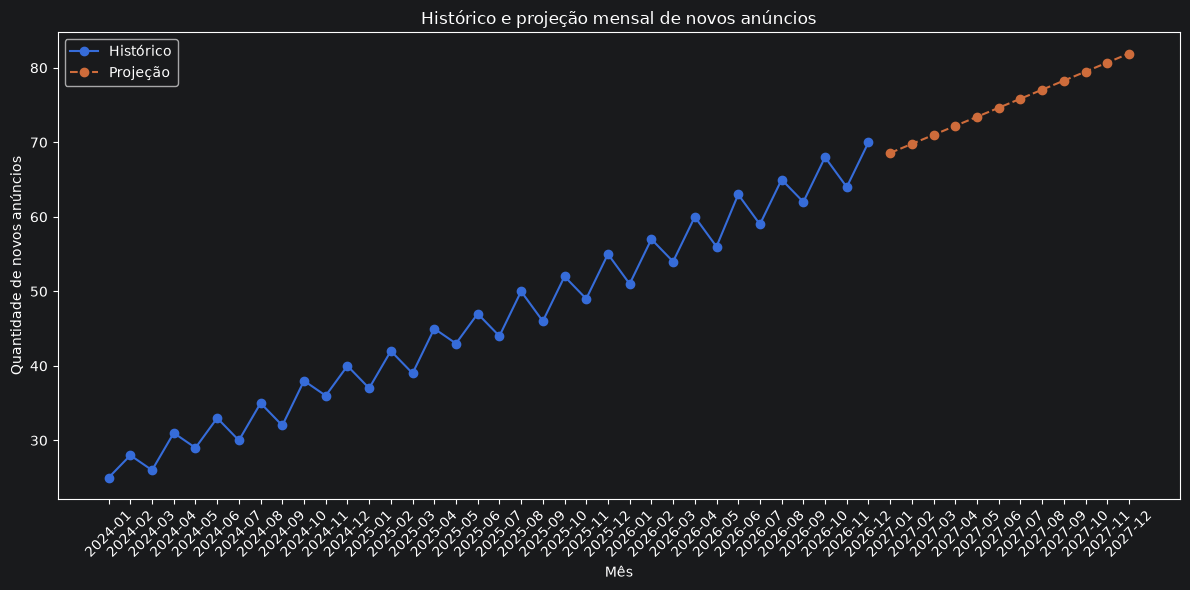

In [179]:
plt.figure(figsize=(12, 6))

plt.plot(
    serie_anuncios["mesCriacao"].astype(str),
    serie_anuncios["novosAnuncios"],
    marker="o",
    label="Histórico"
)

plt.plot(
    projecoes_futuras["mes"].astype(str),
    projecoes_futuras["novosAnunciosEstimados"],
    marker="o",
    linestyle="--",
    label="Projeção"
)

plt.title("Histórico e projeção mensal de novos anúncios")
plt.xlabel("Mês")
plt.ylabel("Quantidade de novos anúncios")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### 7.5 Projeções por horizonte

Além das projeções mensais, serão calculadas estimativas acumuladas para os horizontes de 1, 3, 6 e 12 meses.

Cada horizonte será obtido a partir da soma das previsões mensais correspondentes. Dessa forma, a estimativa de 3 meses, por exemplo, representa a quantidade total de novos anúncios prevista para os três primeiros meses futuros.

Esses horizontes permitem apresentar no Dashboard diferentes perspectivas sobre a quantidade de novos anúncios esperada para períodos futuros.

In [180]:
previsao_1_mes = (
    projecoes_futuras["novosAnunciosEstimados"]
    .iloc[:1]
    .sum()
)

previsao_3_meses = (
    projecoes_futuras["novosAnunciosEstimados"]
    .iloc[:3]
    .sum()
)

previsao_6_meses = (
    projecoes_futuras["novosAnunciosEstimados"]
    .iloc[:6]
    .sum()
)

previsao_12_meses = (
    projecoes_futuras["novosAnunciosEstimados"]
    .iloc[:12]
    .sum()
)

print(f"Próximo mês: {previsao_1_mes:.2f}")
print(f"Próximos 3 meses: {previsao_3_meses:.2f}")
print(f"Próximos 6 meses: {previsao_6_meses:.2f}")
print(f"Próximos 12 meses: {previsao_12_meses:.2f}")

Próximo mês: 68.57
Próximos 3 meses: 209.36
Próximos 6 meses: 429.64
Próximos 12 meses: 902.94


### 7.6 Resumo das projeções por horizonte

Os resultados dos diferentes horizontes serão organizados em uma única estrutura para facilitar sua interpretação e futura utilização pelo serviço de Analytics.

Os valores decimais produzidos pelo modelo serão preservados para fins analíticos. Para apresentação ao usuário no Dashboard, também será criada uma versão arredondada das estimativas, uma vez que a quantidade de anúncios representa uma contagem discreta.

In [181]:
resumo_horizontes = pd.DataFrame({
    "horizonteMeses": [1, 3, 6, 12],
    "novosAnunciosEstimados": [
        previsao_1_mes,
        previsao_3_meses,
        previsao_6_meses,
        previsao_12_meses
    ]
})

resumo_horizontes

,horizonteMeses,novosAnunciosEstimados
0,1,68.574603
1,3,209.362033
2,6,429.638739
3,12,902.936165


In [182]:
resumo_horizontes["valorArredondado"] = (
    resumo_horizontes["novosAnunciosEstimados"]
    .round()
    .astype(int)
)

resumo_horizontes

,horizonteMeses,novosAnunciosEstimados,valorArredondado
0,1,68.574603,69
1,3,209.362033,209
2,6,429.638739,430
3,12,902.936165,903


### 7.7 Preparação dos resultados para apresentação

Além dos valores numéricos, serão preparados textos resumidos para facilitar a apresentação das projeções no Dashboard.

Os textos utilizarão os valores arredondados, enquanto os valores decimais originais continuarão disponíveis para processamento e análise.

In [184]:
textos_horizontes = [
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[0]} novos anúncios no próximo mês",
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[1]} novos anúncios nos próximos 3 meses",
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[2]} novos anúncios nos próximos 6 meses",
    f"Aproximadamente {resumo_horizontes['valorArredondado'].iloc[3]} novos anúncios nos próximos 12 meses"
]

resumo_horizontes["texto"] = textos_horizontes

resumo_horizontes

,horizonteMeses,novosAnunciosEstimados,valorArredondado,texto
0,1,68.574603,69,Aproximadamente 69 novos anúncios no próximo mês
1,3,209.362033,209,Aproximadamente 209 novos anúncios nos próximo...
2,6,429.638739,430,Aproximadamente 430 novos anúncios nos próximo...
3,12,902.936165,903,Aproximadamente 903 novos anúncios nos próximo...


## 8. Conclusão

O experimento permitiu avaliar a aplicação de técnicas de análise preditiva para estimar a quantidade de novos anúncios que poderão ser publicados no Trocabook com base no histórico mensal de criação de anúncios.

Inicialmente, os registros individuais foram transformados em uma série temporal mensal utilizando o campo `dataCriacao`. A análise exploratória identificou uma tendência geral de crescimento na quantidade de anúncios ao longo do período simulado, embora tenham ocorrido variações entre meses consecutivos.

Para avaliar a capacidade de previsão, os dados foram separados cronologicamente em conjuntos de treinamento e teste. O baseline de persistência apresentou MAE de aproximadamente 4,83 anúncios e RMSE de aproximadamente 4,98 anúncios. A Regressão Linear apresentou MAE de aproximadamente 2,40 anúncios e RMSE de aproximadamente 2,53 anúncios, obtendo menores erros no conjunto de teste utilizado neste experimento.

Após a avaliação, a Regressão Linear foi treinada novamente utilizando todo o histórico disponível e utilizada para gerar projeções para os 12 meses seguintes. A partir das previsões mensais, foram calculadas estimativas acumuladas para os horizontes de 1, 3, 6 e 12 meses.

Os resultados estimaram aproximadamente 69 novos anúncios para o próximo mês, 209 para os próximos 3 meses, 430 para os próximos 6 meses e 903 para os próximos 12 meses.

É importante destacar que os resultados foram obtidos a partir de dados simulados e, portanto, não representam previsões reais sobre o crescimento futuro do Trocabook. O experimento tem como objetivo validar a metodologia e a estrutura necessária para a futura utilização dos dados reais armazenados no Firestore.

Com a disponibilidade de um histórico real de anúncios, o desempenho do modelo deverá ser novamente avaliado. Caso a série apresente características diferentes das observadas na simulação, como sazonalidade, alterações de tendência ou maior variabilidade, outros modelos e estratégias de previsão poderão ser comparados.

Dessa forma, o experimento estabelece uma base para a implementação da funcionalidade de previsão de novos anúncios no serviço de Analytics, permitindo futuramente disponibilizar essas informações no Dashboard administrativo do Trocabook.